In [53]:
import os
import random
import sys
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import SparkSession
from pyspark.sql.types import ArrayType, FloatType, StringType, StructField, StructType
from pyspark.sql import functions as F

from data_preparation import process_file_path

In [54]:
from pathlib import Path
import random

script_dir = Path.cwd()
audio_dir = script_dir / "data" / "gztan"

files = sorted(str(f) for f in audio_dir.glob("*/*.wav"))
random.Random(42).shuffle(files)

# Un archivo por cada folder (género), ordenado alfabéticamente por género
seen_genres = {}
for f in files:
    genre = Path(f).parent.name
    if genre not in seen_genres:
        seen_genres[genre] = f

sample_files = [seen_genres[g] for g in sorted(seen_genres)]

# Inicializar sesión de spark para procesamiento en paralelo

In [55]:
n_cores = os.cpu_count() or 4

spark = (
    SparkSession.builder.appName("PySpark_Audio_Preprocess")
    .master(f"local[{n_cores}]")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
sc = spark.sparkContext

In [56]:
SR = 22050
DURATION = 30

audio_samples = spark.createDataFrame(
    [
      (Path(f).parent.name, librosa.load(f, sr=SR, mono=True, duration=DURATION)[0].tolist())
      for f in sample_files
    ],
    schema=["genre", "audio"]
)

audio_samples.show(10)

+---------+--------------------+
|    genre|               audio|
+---------+--------------------+
|    blues|[-0.0083618164062...|
|classical|[-0.0396423339843...|
|  country|[0.04299926757812...|
|    disco|[-0.0800170898437...|
|   hiphop|[0.02114868164062...|
|     jazz|[-0.023681640625,...|
|    metal|[0.14898681640625...|
|      pop|[0.12274169921875...|
|   reggae|[0.02847290039062...|
|     rock|[0.08343505859375...|
+---------+--------------------+



# Muestra de audio de los diferentes géneros

Este es únicamente visualización, ver un poco como se ven las muestras de audio y difieren un poco entre los géneros, pero no será lo que analizaremos. 
Para ello utilizaremos las frecuencias de Mel (MFCC) que se ven más adelante.

* Blues tiene un rango de amplitudo como entre +-0.5, con segmentos bastante rápidos  fuertes y luego bajando el volumen un poco más. \
* La música clásica tiene segmentos con amplitudes muy bajas y luego altas, como entre +-0.5 y luego hasta llegar a 2. \
* Country se parece al blues, pero con amplitudes ligeramente menores y mayor densidad. \
* Al contrario a country, Disco tiene una menor densidad con picos independientes bastante superiores a las amplitudes normales de la canción; las cuales van de -0.25 a 0.5. \
* Hiphop tiene beats marcados casi cada 5 segundos. \
* Simplemente en el análisis de audio se puede ver que pop tiene picos que constantemente chocan con 1 y -1, que pues indica que tiene una amplitud más alta constante. Jazz tiene patrones como más triangulares como de un beat fuerte seguido de musica más silenciosa hasta el siguiente beat, estos parecen ser relativamente constantes, como del segundo 3 - 12 - 18 - 28. estos son aproximaciones visuales de donde se están ejecutando los beats, que podrían ser en tiempos de 3 segundos. Igual, su escala es menor, llendo de -0.4 a 6, teniendo un volumen inferior comparado a la canción de pop. \
* Raggae es más regular en comparación a Jazz, con un rango como entre +-8. \
* Por su parte, rock parece ser el que menos degradados tiene, se muestra mayor densidad en la música, como menos picos solitarios en los extremos. Igual muestra una amplitud como entre +-8, puede ser por los instrumentos que utiliza que son más estruendosos, su sonido persiste, y tiene un ritmo rápido. \
* Metal, es bastante similar al rock pero con aún mayor densidd en su amplitud, pese a tener una amplitud general algo más baja, es más constante y con niveles altos. 

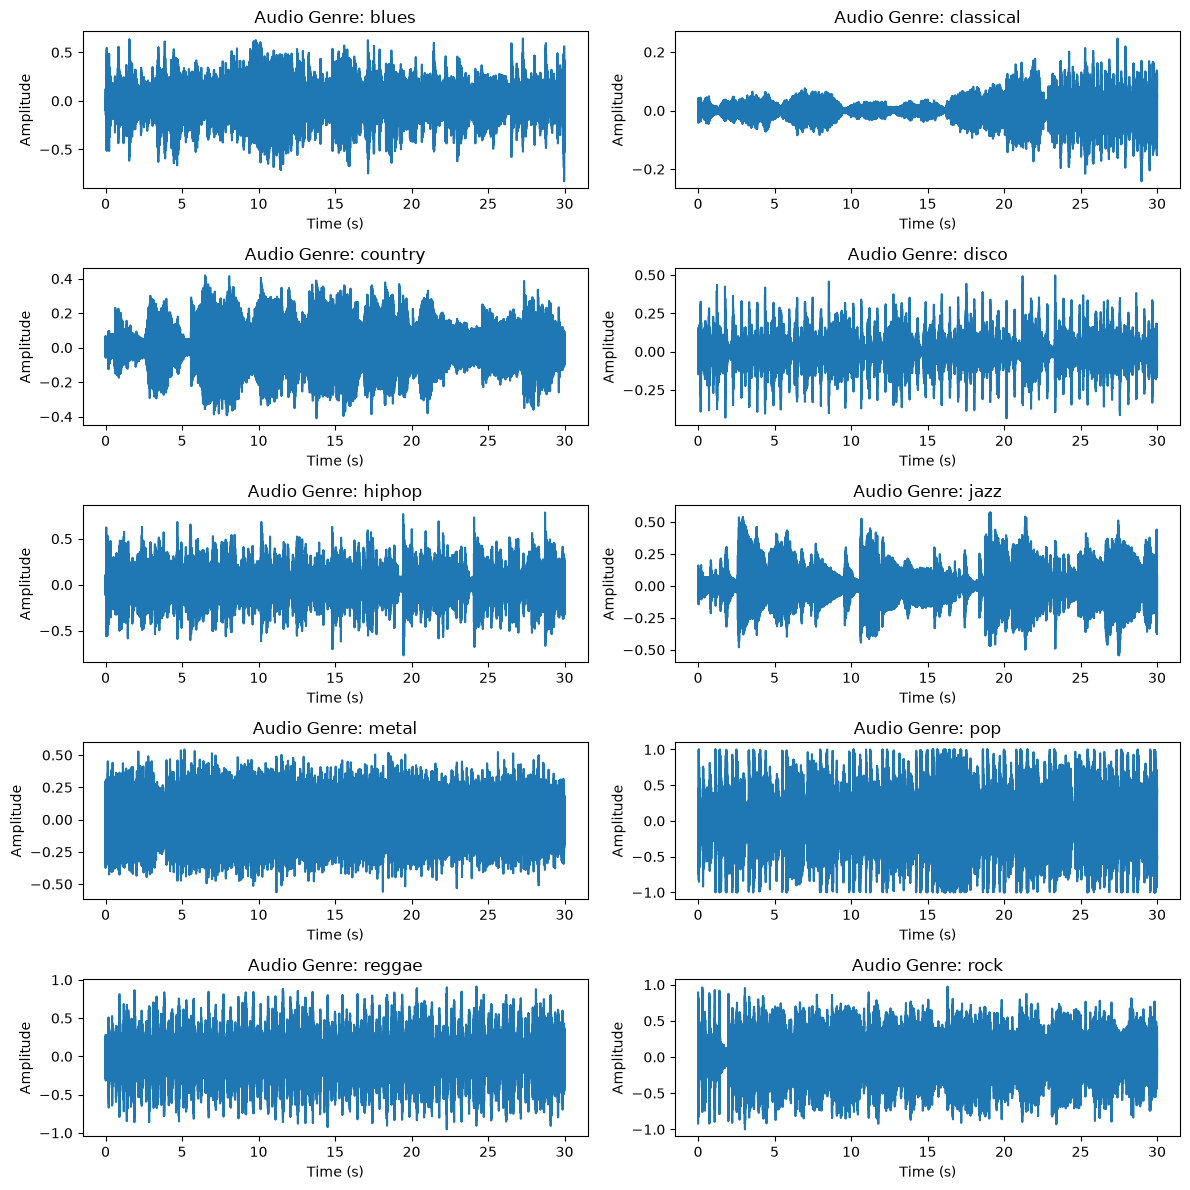

In [59]:
fig, ax = plt.subplots(nrows=5, ncols=2, figsize=(12, 12))

for idx, row in enumerate(audio_samples.collect()):
    signal = row["audio"]
    times = np.arange(len(signal)) / SR
    
    curr_ax = ax[idx // 2, idx % 2]
    curr_ax.plot(times, signal)
    
    curr_ax.set(title=f"Audio Genre: {row['genre']}", xlabel="Time (s)", ylabel="Amplitude")

plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.tight_layout()
plt.show()

In [44]:
def process_partition(file_iter):
    """
    Procesa una partición completa de rutas en cada worker de spark
    """
    results = []
    for r in map(process_file_path, file_iter):
        if r is not None:
            label, mfcc = r
            results.append((label, mfcc.tolist()))
    return results

In [45]:
rdd_features = sc.parallelize(files).mapPartitions(process_partition)
# 2. Definir el esquema explícito para el DataFrame
schema = StructType(
    [
        StructField("label", StringType(), True),
        StructField("mfcc", ArrayType(ArrayType(FloatType())), True),
    ]
)

# 3. Crear el Spark DataFrame
df = spark.createDataFrame(rdd_features, schema=schema)
df.show(5)

+------+--------------------+
| label|                mfcc|
+------+--------------------+
|   pop|[[-138.54951, -30...|
|  jazz|[[-294.78967, -31...|
|reggae|[[-112.43686, -99...|
|  rock|[[21.553215, 43.8...|
| blues|[[-341.0304, -335...|
+------+--------------------+
only showing top 5 rows


Con el diagrama de caja bigote podemos ver cómo se parecen entre ellos los géneros mediante las amplitudes usuales que se presentan las canciones. Esto ayuda a ver los géneros más únicos o que más se diferencian del resto al igual de aquellos que más se parecen entre sí. Por ejemplo, blues se parece a country aunque con un rango un poco menor, disco suele tener frecuencias más altas al resto, jazz y metal igual presentan frecuencias similares, aunque el jazz se extiende más que el metal, y pop y reggae igual muestran frecuencias similares. Rock tiene una media y quartiles 2-3 más extensos en comparación al resto de géneros, y tiene una media similar a jazz y metal. 

c:\Users\Santiago\Documents\Personal\IA\bigdata\venv\Lib\site-packages\librosa\core\spectrum.py:3004: UserWarning: n_fft=2048 is too large for input signal of length=1292
  stft(


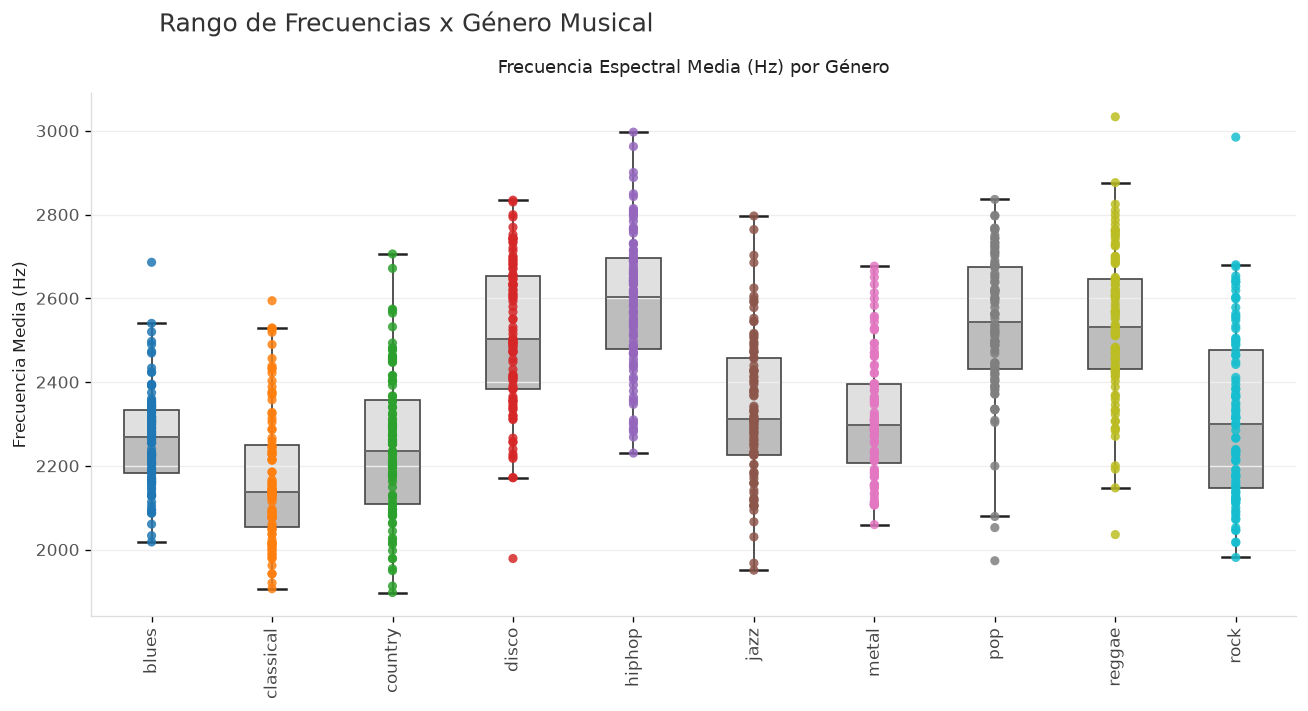

In [50]:
import librosa
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 1. Extraer la frecuencia dominante promedio (Centroide Espectral en Hz) de cada audio
records = []

# Sin enumerate(), así 'row' es directamente la fila de PySpark
for row in df.collect():  
    signal = np.array(row["mfcc"], dtype=np.float32)
    
    freq_mean = np.mean(librosa.feature.spectral_centroid(y=signal, sr=SR))
    
    records.append({
        "label": row["label"],
        "frequency_hz": freq_mean
    })

df_plot = pd.DataFrame(records).sort_values("label")
labels = df_plot["label"].unique()

# 2. Configurar el estilo visual idéntico a la referencia
fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
ax.set_facecolor("white")

sns.boxplot(
    data=df_plot,
    x="label",
    y="frequency_hz",
    ax=ax,
    width=0.45,
    showfliers=False,
    boxprops=dict(facecolor="none", edgecolor="#444444", linewidth=1, zorder=3),
    medianprops=dict(color="#666666", linewidth=1.2, zorder=4),
    whiskerprops=dict(color="#333333", linewidth=1, zorder=2),
    capprops=dict(color="#222222", linewidth=1.5, zorder=2)
)

# 3. Efecto de dos tonos de gris (Q1-Mediana oscuro, Mediana-Q3 claro)
for i, label in enumerate(labels):
    vals = df_plot[df_plot["label"] == label]["frequency_hz"]
    q25, q50, q75 = np.percentile(vals, [25, 50, 75])
    
    rect_low = Rectangle((i - 0.225, q25), 0.45, q50 - q25, facecolor="#BDBDBD", zorder=1)
    rect_high = Rectangle((i - 0.225, q50), 0.45, q75 - q50, facecolor="#E0E0E0", zorder=1)
    
    ax.add_patch(rect_low)
    ax.add_patch(rect_high)

# 4. Superponer los puntos individuales coloreados por género
sns.stripplot(
    data=df_plot,
    x="label",
    y="frequency_hz",
    hue="label",
    palette="tab10",
    jitter=False,
    size=5.5,
    alpha=0.85,
    legend=False,
    ax=ax,
    zorder=5
)

# 5. Detalles finales de ejes, cuadrícula y títulos
ax.yaxis.grid(True, linestyle="-", color="#EEEEEE", zorder=0)
ax.xaxis.grid(False)
sns.despine(top=True, right=True)
ax.spines["left"].set_color("#DDDDDD")
ax.spines["bottom"].set_color("#DDDDDD")

plt.suptitle("Rango de Frecuencias x Género Musical", x=0.125, ha="left", fontsize=15, color="#333333")
ax.set_title("Frecuencia Espectral Media (Hz) por Género", fontsize=11, color="#222222", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Frecuencia Media (Hz)", fontsize=10, color="#222222")
plt.xticks(rotation=90, fontsize=10, color="#444444")
plt.yticks(fontsize=10, color="#555555")

plt.tight_layout()
plt.show()

# Frecuancias de Mel (MFCC)

Esta es una muestra de las frecuencias de Mel, esto es la información real que se le pasará al modelo para procesamiento y del cual interpretará el género de la canción

Las gráficas de frecuencias de Mel, la extracción de MFCC utiliza 13 niveles de detalle ordenado de lo general a lo fino, de ahí el eje vertical que va de 0 a 12, mientras que el eje X hace referencia a frames en el tiempo. 

La fila 0 es el volumne general del audio
La 1 es balance entre graves y agudos,
2 al 5 son la forma principal de instrumento o voz
de 6 a 12 son detalles finos como rasgueo, aire de una flauta, etc.

Los colores se podría interpretar que los colores morados o azules socuros son silencio o volúmenes bajos, o ausencia de características; verdes son estado neutro y amarillo significa que está muy presente en el momento. 

En la primera gráfica se muestra el jazz. El morado de hasta abajo está muy presente seguido de un amarillo intenso. Se podría entender que este género presenta pausas seguidas de tonos altos. En rock y Hiphop estos son más constantes sin tanta pausa y un volumen constante alto. La música clásica igual parece tener pausas, pero menos notorias que en jazz. 

Jazz parece tener mucho más detalle fino que el resto de los géneros, debido a sus tonos son más verdosos, pero rock tiene menos de este detalle fino, con una mayor precencia de colores azules. Las líneas verticales que presenta junto con Hiphop pertenecen a golpes de instrumentos de percusión. 
Mientras que Jazz y Clásica son degradados suaves, indicando que su múscia tiende a transicionar de notas más suavemente o tiene notas sostenidas.

Jazz igual tiene un rango más pronunciado con mínimos de hasta -600 y máximos de 200 mientras que hiphop tiene la menor escala de -300 a 100, la mitad de rango que jazz. 

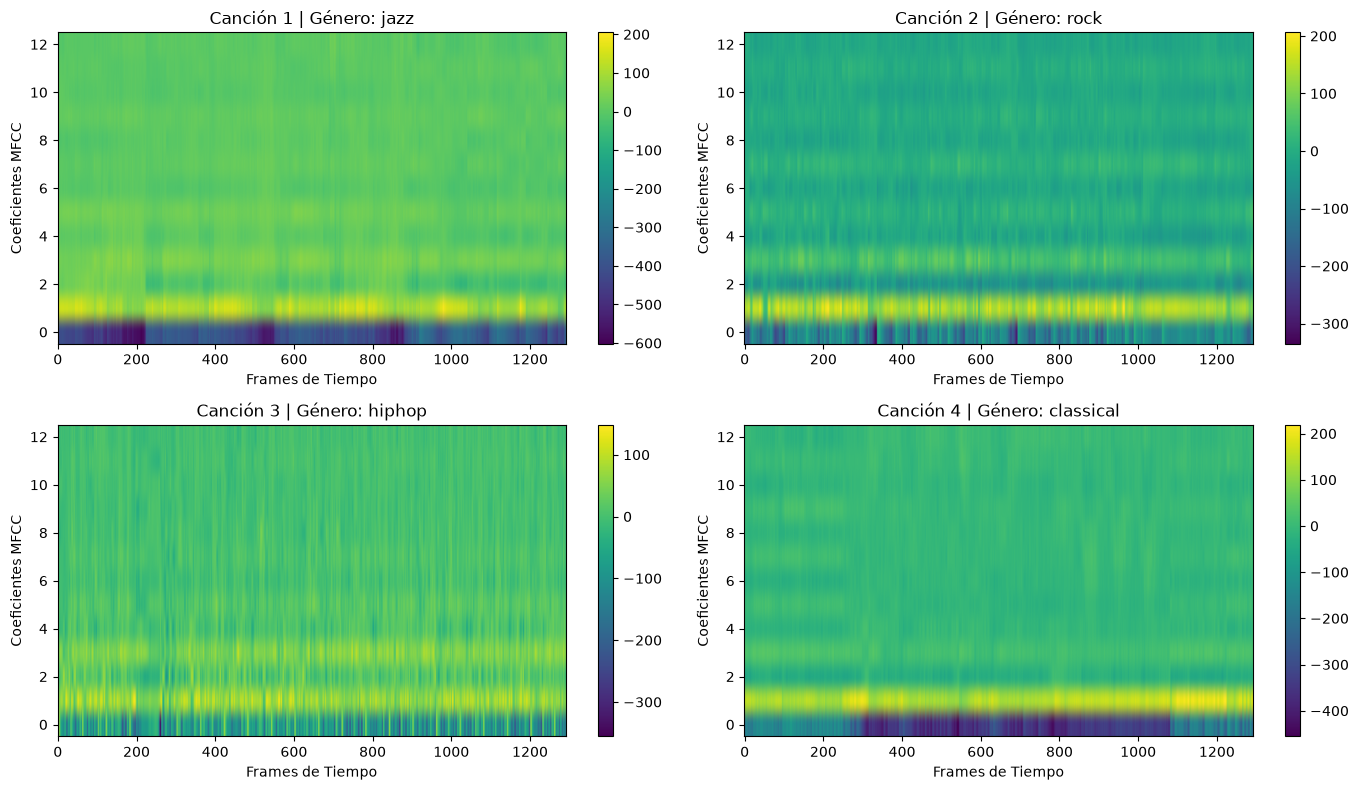

In [ ]:
samples = df.sample(withReplacement=False, fraction=1.0).orderBy(F.rand()).limit(4).collect()

# 2. Configurar la figura con 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, row in enumerate(samples):
    genre = row["label"]
    # Convertir la lista anidada devuelta por Spark a un array de Numpy
    mfcc_matrix = np.array(row["mfcc"]) 

    ax = axes[i]
    # Graficar la matriz MFCC como heatmap (Coeficientes vs. Tiempo)
    img = ax.imshow(mfcc_matrix, aspect='auto', origin='lower', cmap='viridis')
    
    ax.set_title(f"Canción {i+1} | Género: {genre}")
    ax.set_xlabel("Frames de Tiempo")
    ax.set_ylabel("Coeficientes MFCC")
    fig.colorbar(img, ax=ax)

plt.tight_layout()
plt.show()

# Preparación de los datos

La preparación de los datos consiste en seleccionar los archivos de audio y preprocesarlos para extraer las frecuencias de Mel (MFCC) para el procesamiento posterior que podrá identificar el género de dicha canción

In [ ]:
SR = 22050
N_FFT = 2048
N_MFCC = 13
HOP_LENGTH = 512
DURATION = 30  # segundos
N_SAMPLES = SR * DURATION  # 661500
BATCH_SIZE = 50

In [ ]:
def preprocess_audio(audio):
    audio = np.asarray(audio, dtype=np.float32)
    if len(audio) > N_SAMPLES:
        return audio[:N_SAMPLES]
    return np.pad(audio, (0, N_SAMPLES - len(audio)))


def extract_features(audio, sr=SR):
    return librosa.feature.mfcc(
        y=audio, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mfcc=N_MFCC
    ).astype(np.float32)  # (13, 1293)


def process_file_path(file_path_str):
    """Corre en los workers de Spark. Devuelve (path, mfcc) o None."""
    file_path = Path(file_path_str)
    try:
        audio, _ = librosa.load(file_path, sr=SR, mono=True, duration=DURATION)
        audio = preprocess_audio(audio)
        return (file_path.parent.name, extract_features(audio))
    except Exception:
        print(f"Error procesando {file_path}")
        return None


def make_batch_processor(output_dir):
    """Devuelve la función que corre en cada worker: procesa su lote y lo guarda."""

    def process_and_save(batch_idx, file_iter):
        results = [r for r in map(process_file_path, file_iter) if r is not None]
        if not results:
            return iter([(batch_idx, 0)])

        genres, mfccs = zip(*results)
        out_path = Path(output_dir) / f"batch_{batch_idx:04d}.npz"
        np.savez_compressed(
            out_path,
            X=np.stack(mfccs),
            y=np.array(genres),
        )
        return iter([(batch_idx, len(results))])

    return process_and_save

In [ ]:
n_cores = os.cpu_count() or 4

sc = spark.sparkContext

script_dir = Path.cwd()
output_dir = script_dir / "data" / "batches"
output_dir.mkdir(parents=True, exist_ok=True)
audio_dir = script_dir / "data" / "gztan"

files = sorted(str(f) for f in audio_dir.glob("*/*.wav"))
random.Random(42).shuffle(files)

n_batches = -(-len(files) // BATCH_SIZE)  # división techo
print(f"Canciones encontradas: {len(files)}")
print(f"Archivos .npz esperados: {n_batches}")

summary = (
	sc.parallelize(files, numSlices=n_batches)
	.mapPartitionsWithIndex(make_batch_processor(str(output_dir)))
	.collect()
)

total = sum(n for _, n in summary)
print(f"Procesamiento completado: {total} canciones en {len(summary)} archivos")

Canciones encontradas: 1000
Archivos .npz esperados: 20
Procesamiento completado: 999 canciones en 20 archivos


# Modelo

Quería hacer el mismo proyecto que en la clase de Benji para comparar el rendimiento de pyspark que puede utilizar todos los cores de mi computadora y el procesamiento en paralelo en comparación con tensorflow. Pero resultó que la arquitectura que implementé en ese no es posible ni con pyspark mllib ni ml, por lo que solo estoy utilizando capas densas para la extracción de características y clasificación del modelo.

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
from pyspark.ml.feature import StandardScaler, StringIndexer
from pyspark.ml.linalg import Vectors
from pyspark.ml.classification import MultilayerPerceptronClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

BATCH_SIZE = 16

X_list, y_list = [], []
for f in sorted(output_dir.glob("batch_*.npz")):
    d = np.load(f)
    X_list.append(d["X"])
    y_list.append(d["y"])

X = np.concatenate(X_list)                 # (N, 13, 1293)
y = np.concatenate(y_list)                 # (N,)
feats = np.concatenate([X.mean(axis=2), X.std(axis=2)], axis=1).astype(np.float64)
print(f"Dataset: {X.shape[0]} canciones, {feats.shape[1]} features")

rows = [(str(g), Vectors.dense(v)) for g, v in zip(y, feats)]
df = spark.createDataFrame(rows, ["genre", "features_raw"])

Dataset: 999 canciones, 26 features


In [ ]:
indexer = StringIndexer(inputCol="genre", outputCol="label").fit(df)
df = indexer.transform(df)
class_names = indexer.labels
num_classes = len(class_names)


In [ ]:
# Split 70 - 15 - 15
train_df, val_df, test_df = df.randomSplit([0.70, 0.15, 0.15], seed=42)
print(f"Train: {train_df.count()} | Val: {val_df.count()} | Test: {test_df.count()}")

Train: 702 | Val: 162 | Test: 135


In [ ]:
scaler = StandardScaler(
    inputCol="features_raw", outputCol="features", withMean=True, withStd=True
).fit(train_df)

train_df = scaler.transform(train_df).cache()
val_df = scaler.transform(val_df).cache()
test_df = scaler.transform(test_df).cache()

n_features = feats.shape[1]
print(n_features)

26


## Entrenamiento del modelo
Tuve que usar solo capas densas. Quería hacer el mismo modelo que hice para la calse de Benji para comparar el rendimiento de spark con tensorflow, pero resultó que no tenía las mismas capacidades. Así que cambié las capas convolucionales, max pooling y batch normalization por puras capas densas. 

El modelo tiene un overfit considerable. Parece que con forme pasa el tiempo a la validación le va peor comparado a entrenamiento. En el experimento que había hecho con redes convolutivas hubo un resultado similar, pero la distancia entre entrenamiento y validación era menor, y bajaban igual durante más tiempo. Puede que al solo utilizar redes densas no pueda captar características generales tan facilmente entre géneros. 

Mejor modelo en iteración 80 -> val acc = 0.6605


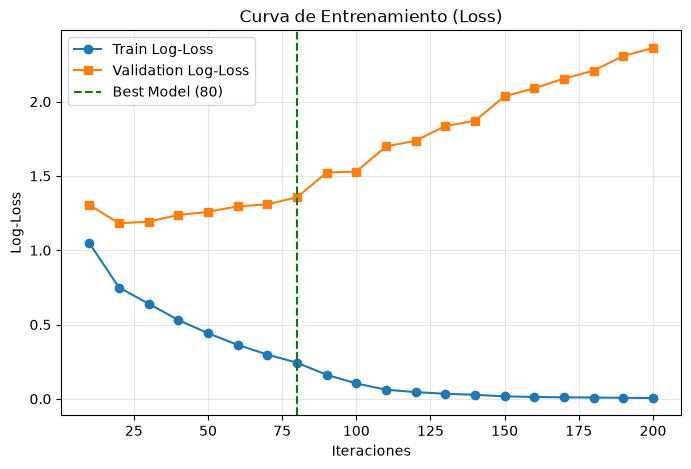

In [66]:
loss_eval = MulticlassClassificationEvaluator(
    labelCol="label", probabilityCol="probability", metricName="logLoss"
)
acc_eval = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="accuracy"
)

step_iters = 10
total_steps = 20  # 200 iteraciones en total

iters_hist, train_losses, val_losses = [], [], []
current_weights = None

best_model, best_val_acc, best_iter = None, -1.0, None

for step in range(1, total_steps + 1):
    mlp_step = MultilayerPerceptronClassifier(
        layers=[n_features, 64, num_classes],
        maxIter=step_iters,
        blockSize=128,
        seed=42,
        initialWeights=current_weights,  # continúa desde el paso anterior
    )
    m_step = mlp_step.fit(train_df)
    current_weights = m_step.weights
    current_iter = step * step_iters

    # Evaluar loss en train y val
    train_preds = m_step.transform(train_df)
    val_preds = m_step.transform(val_df)

    t_loss = loss_eval.evaluate(train_preds)
    v_loss = loss_eval.evaluate(val_preds)
    val_acc = acc_eval.evaluate(val_preds)

    iters_hist.append(current_iter)
    train_losses.append(t_loss)
    val_losses.append(v_loss)

    # Guardar el mejor modelo según validation accuracy
    if val_acc > best_val_acc:
        best_model, best_val_acc, best_iter = m_step, val_acc, current_iter

print(f"Mejor modelo en iteración {best_iter} -> val acc = {best_val_acc:.4f}")

# Graficar Loss
plt.figure(figsize=(8, 5))
plt.plot(iters_hist, train_losses, marker="o", label="Train Log-Loss")
plt.plot(iters_hist, val_losses, marker="s", label="Validation Log-Loss")
plt.axvline(
    best_iter, color="green", linestyle="--", label=f"Best Model ({best_iter})"
)
plt.xlabel("Iteraciones")
plt.ylabel("Log-Loss")
plt.title("Curva de Entrenamiento (Loss)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

La curva Roc ayuda a explicar el entrenamiento del modelo y cómo se va adaptando a la múscia y su tasa de verdadero positivos. Como se puede ver hay géneros que entiende y aprende a identificarlos rápidamente como clásica o rock, pero otros que se tarda más; como es el caso de Disco o Pop. En cambio para este ejemplo creo que más adecuado es la gráfica de la derecha que es la PR-AUC. Esta indica la precisión y Recall del modelo, tomando en cuenta capacidad para identificar falsos positivos, y verdaderos positivos. En esta lo que nos interesa es que el valor disminuya. Por ejemplo, en el comportamiento que se muestra hay dos tendencias. Géneros que elegía siempre seguido, como pop, jazz o clásica, mientras que otros empiezan de abajo y suben como es el caso de disco o country. 

Si un género es alto en ROC pero bajo en PR indica que el modelo sabe distinguir que una canción no es de dicho género, pero no es tan bueno distinguiendola entre los demás géneros, como es el caso de rock. 


c:\Users\Santiago\Documents\Personal\IA\bigdata\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


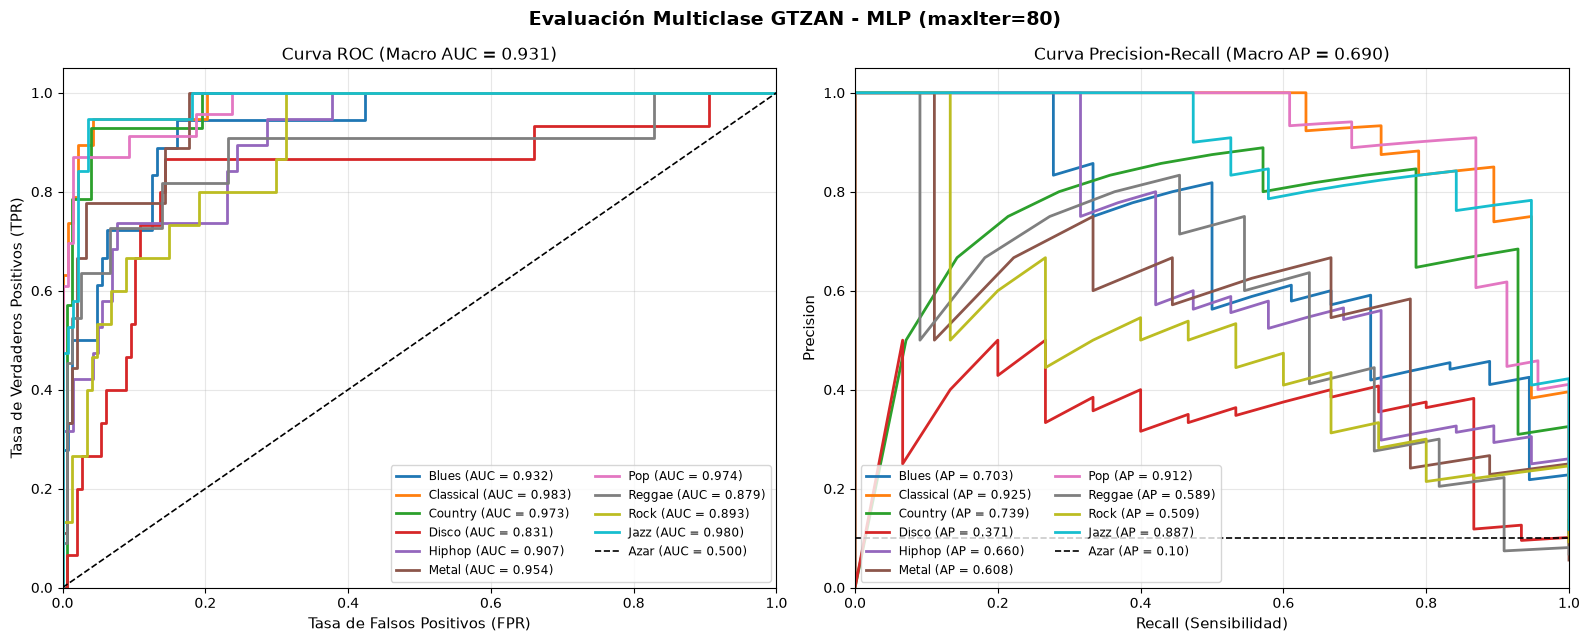

In [83]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import (
    auc,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
)
from sklearn.preprocessing import label_binarize

generos = [
    "blues",
    "classical",
    "country",
    "disco",
    "hiphop",
    "metal",
    "pop",
    "reggae",
    "rock",
    "jazz",
]

# 1. Obtener predicciones y probabilidades desde PySpark
preds_df = best_model.transform(val_df).select(
    "label", vector_to_array("probability").alias("probs")
)
pdf = preds_df.toPandas()

y_true = pdf["label"].values
y_score = np.vstack(pdf["probs"].values)
n_classes = len(generos)

# 2. Binarizar etiquetas para One-vs-Rest
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# 3. Crear figura con dos subgráficas lado a lado (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))
colors = plt.cm.tab10(np.linspace(0, 1, n_classes))

aucs, aps = [], []

for i, (genero, color) in enumerate(zip(generos, colors)):
    # --- Gráfica Izquierda: Curva ROC ---
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    ax1.plot(
        fpr,
        tpr,
        color=color,
        lw=2,
        label=f"{genero.capitalize()} (AUC = {roc_auc:.3f})",
    )

    # --- Gráfica Derecha: Curva Precision-Recall ---
    precision, recall, _ = precision_recall_curve(
        y_true_bin[:, i], y_score[:, i]
    )
    ap_score = average_precision_score(y_true_bin[:, i], y_score[:, i])
    aps.append(ap_score)
    ax2.plot(
        recall,
        precision,
        color=color,
        lw=2,
        label=f"{genero.capitalize()} (AP = {ap_score:.3f})",
    )

# Configuración panel izquierdo (ROC)
ax1.plot([0, 1], [0, 1], "k--", lw=1.2, label="Azar (AUC = 0.500)")
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel("Tasa de Falsos Positivos (FPR)", fontsize=11)
ax1.set_ylabel("Tasa de Verdaderos Positivos (TPR)", fontsize=11)
ax1.set_title(f"Curva ROC (Macro AUC = {np.mean(aucs):.3f})", fontsize=12)
ax1.legend(loc="lower right", fontsize=8.5, ncol=2)
ax1.grid(alpha=0.3)

# Configuración panel derecho (PR-AUC)
baseline = 1.0 / n_classes
ax2.axhline(
    baseline,
    color="k",
    linestyle="--",
    lw=1.2,
    label=f"Azar (AP = {baseline:.2f})",
)
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel("Recall (Sensibilidad)", fontsize=11)
ax2.set_ylabel("Precision", fontsize=11)
ax2.set_title(
    f"Curva Precision-Recall (Macro AP = {np.mean(aps):.3f})", fontsize=12
)
ax2.legend(loc="lower left", fontsize=8.5, ncol=2)
ax2.grid(alpha=0.3)

plt.suptitle(
    f"Evaluación Multiclase GTZAN - MLP (maxIter={best_iter})",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Evaluación

El modelo parece tener un sobreajuste, dado que las métricas de entrenamiento son mejores a las de validación y pruebas por casi 30%. Pese a eso, validación y pruebas se mantienen en un rango bastante similar, si acaso pruebas con resultados un poco mejores. Puede ser porque había una mayor precensia de algún género que se le facilita en detectar en pruebas que validación. 

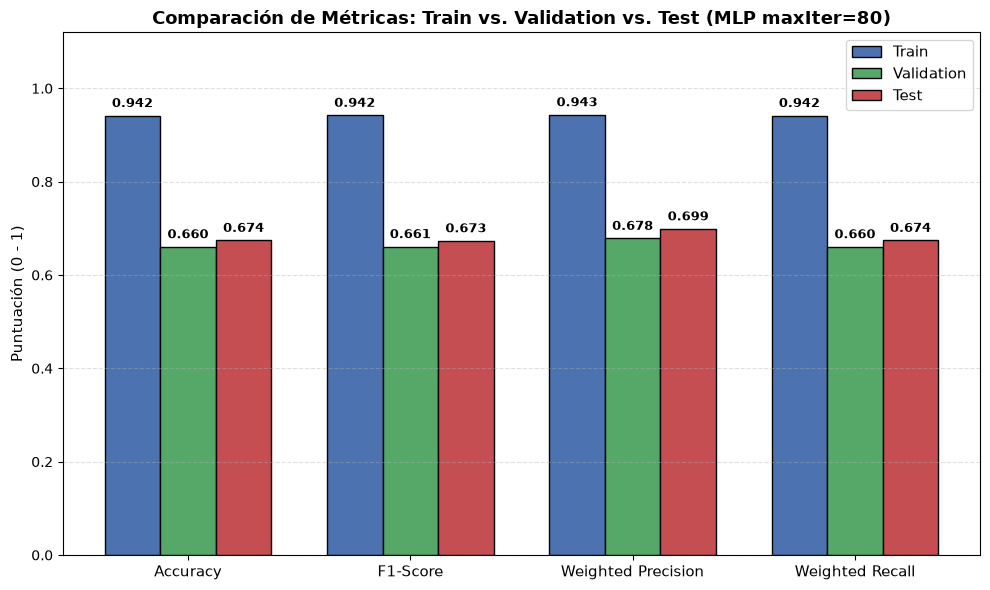

In [84]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.ml.evaluation import MulticlassClassificationEvaluator


def evaluate(model, data):
    preds = model.transform(data)
    metrics = ["accuracy", "f1", "weightedPrecision", "weightedRecall"]
    results = {}
    for metric in metrics:
        ev = MulticlassClassificationEvaluator(
            labelCol="label", predictionCol="prediction", metricName=metric
        )
        results[metric] = ev.evaluate(preds)
    return preds, results


# 1. Evaluar los tres conjuntos
_, train_res = evaluate(best_model, train_df)
_, val_res = evaluate(best_model, val_df)
test_preds, test_res = evaluate(best_model, test_df)

# 2. Preparar datos para graficar
metric_keys = ["accuracy", "f1", "weightedPrecision", "weightedRecall"]
metric_labels = ["Accuracy", "F1-Score", "Weighted Precision", "Weighted Recall"]

train_vals = [train_res[m] for m in metric_keys]
val_vals = [val_res[m] for m in metric_keys]
test_vals = [test_res[m] for m in metric_keys]

x = np.arange(len(metric_labels))
width = 0.25  # ancho de cada barra

# 3. Crear gráfica de barras agrupadas
fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(
    x - width, train_vals, width, label="Train", color="#4C72B0", edgecolor="black"
)
rects2 = ax.bar(
    x, val_vals, width, label="Validation", color="#55A868", edgecolor="black"
)
rects3 = ax.bar(
    x + width, test_vals, width, label="Test", color="#C44E52", edgecolor="black"
)

# Añadir el valor numérico encima de cada barra
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.3f}",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )

# Configuración estética
ax.set_ylabel("Puntuación (0 - 1)", fontsize=11)
ax.set_title(
    f"Comparación de Métricas: Train vs. Validation vs. Test (MLP maxIter={best_iter})",
    fontsize=13,
    fontweight="bold",
)
ax.set_xticks(x)
ax.set_xticklabels(metric_labels, fontsize=11)
ax.set_ylim(0, 1.12)  # margen superior para que quepan las etiquetas numéricas
ax.legend(loc="upper right", fontsize=10.5)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [79]:
print("\n=== Resumen ===")
print(pd.DataFrame(
    {"train": train_res, "val": val_res, "test": test_res}
).round(4))
print(f"Baseline aleatorio: {1 / num_classes:.4f}")

# Reporte por clase y matriz de confusión (test es pequeño, se puede collect)
pdf = test_preds.select("label", "prediction").toPandas()
y_true = pdf["label"].astype(int)
y_pred = pdf["prediction"].astype(int)


=== Resumen ===
                    train     val    test
accuracy           0.9416  0.6605  0.6741
f1                 0.9421  0.6607  0.6732
weightedPrecision  0.9434  0.6784  0.6988
weightedRecall     0.9416  0.6605  0.6741
Baseline aleatorio: 0.1000


c:\Users\Santiago\Documents\Personal\IA\bigdata\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Aquí se ve una matriz de la calificación que tuvo cada género en diferentes métricas. En este caso lo más importante sería F1, ya que es el ponderado de precision y recall, tomando en cuenta verdaderos positivos y negativos contra falsos positivos y negativos. En este caso podemos identificar que clásica la pudo identificar en todos los casos con, pero igual la seleccionaba seguido cuando se trataba de otro género, jazz igual la clasifica bien pero en este hay menos precensia de falsos falsos positivos y mayor de falsos positivos. 
Metal la identificó bien sin flasos positivos, pero igual fallo considerablemente. Country, Reggae y Rock parecen ser los géneros que más le cuesta identificar, sobre todo rock, con el peor score en f1 y recall, y Hiphop, blues están como en promedio. 


=== Reporte por género (TEST) ===


,precision,recall,f1-score,support
blues,0.6667,0.5714,0.6154,14.0000
classical,1.0000,0.7500,0.8571,8.0000
country,0.4615,0.5455,0.5000,11.0000
disco,0.8462,0.6111,0.7097,18.0000
hiphop,0.5882,0.7143,0.6452,14.0000
metal,0.6111,1.0000,0.7586,11.0000
pop,0.8750,0.7368,0.8000,19.0000
reggae,0.4706,0.5714,0.5161,14.0000
rock,0.6250,0.3846,0.4762,13.0000
jazz,0.8000,0.9231,0.8571,13.0000



=== Matriz de confusión (TEST) ===


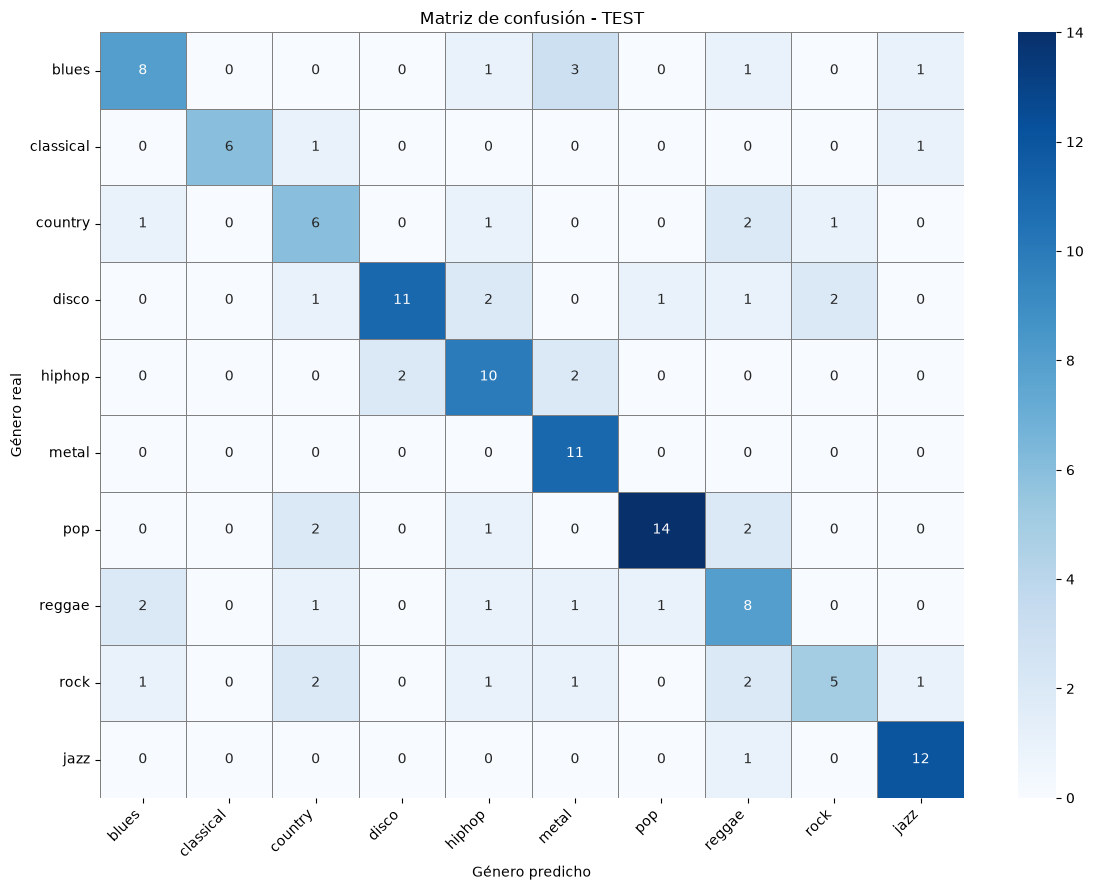

In [80]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix

report = classification_report(
    y_true,
    y_pred,
    labels=range(num_classes),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print("\n=== Reporte por género (TEST) ===")
display(report_df.style
    .format("{:.4f}")
    .background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"])
    .set_caption("Classification Report - TEST")
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(num_classes)
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\n=== Matriz de confusión (TEST) ===")

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    linecolor="gray",
    cbar=True
)

plt.title("Matriz de confusión - TEST")
plt.xlabel("Género predicho")
plt.ylabel("Género real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Metodología y forma de trabajo
1. Primero para el entendimiento de los datos siguiendo la estrategia y teoría proporcionada por Ahmed, et.al (2024) en Musical genre classification using advance audio analysis and deep learning techniques, transformé los archivos de audio en sus transformadas de fourier, para transformar el sonido de la dimensión del tiempo a dimensiones de frecuencia y amplitud, y luego a su frecuencia de Mel (MFCC) y visualicé el espectograma.

**Datos**
Los datos utilizados son la colección de GTZAN, una colección de 1000 canciones de 10 géneros diferentes (100 canciones por género). El dataset tiene un peso de 1.23 GB. 

2. El espectograma es el dato que usa el sistema para el análisis, por lo que transformé todas las canciones a este formato y lo almacené en batches para poder procesarlo. Al intentar procesar todo de jalón me quedaba sin memoria en la computadora, este proyecto se habría beneficiado de una estrategia de big-data utilizando múltiples computadoras para el procesamiento en paralelo. Aunque gracias a Spark, el preprocesamiento de las canciones fue mucho más rápido, ya que aunque no use otras computadoras pudo aprovechar los cores de mi computadora para hacer el procesamiento en paralelo, acción que anteriormente tomaba varios minutos. 

3. Para el modelado de la información utilicé 3 capas densas para la clasificación del género de las canciones. La primera simplemente con la entrada de datos, que es la frecuencia del fragmento de 30 segundos en MFCC, luego otra capa de 64 nodos para identificar patrones de los datos para identificar y una última con la cantidad de clases. Como tal Spark no cuenta con capas convolucionales, max pooling, batch normalization o capas densas como tal. En su lugar terminé usando solo las 3 capas de MulticlassClassificationEvaluator, que cumple una función similar a las capas densas con sigmoid. 

4. En la evaluación del modelo fue mucho más rápido en todo el procesamiento de datos y entrenamiento comparado con mi modelo original, aunque los resultados son un poco peores a mi otra iteración con tensorflow. El aumento en velocidad puede ser por una mayor simplicidad en la arquitectura del modelo, pero igual por la paralelización de las tareas. Mientras que el modelo claramente carece de la complejidad necesaria para explicar os patrones musicales de manera correcta.

	Aún así, el modelo muestra overfit, con una gran precisión en los datos de entrenamiento superior a 90%, pero en validación y pruebas encontrándose alrededor de 60. Algunos géneros los identiica bastante bien, como la música clásica, el metal o el Jazz, pero hay otros que tiene una peor precisión. Por ejemplo, se puede ver que si le atinó a un gran número de veces a las canciones pop, pero igual es el género que más predijo, perdiendo ahí puntos de exactitud por los errores de falso positivo. 

En las gráficas se pueden notar los siguientes aspectos. \
La música clásica y Jazz tienen frecuencias MFCC muy similares, pero a su vez bastante diferentes al resto, sobre todo Jazz, lo que es congruente con lo que muestra la gráfica de las métrcoas donde Jazz y clásica tienen valores generales en las 3 métricas altas, y a su vez con el boxplot de las frecuencias. Estos tienen una mayor proporción de predicciones correctas en estos géneros y tienen frecuencias muy diferentes y amplias. En comparación con country, disco, hiphop, metal y pop tienen propociones mínimos y máximos muy similares, y una disperción menor a clásica y jazz. Igual, blues tuvo buenos resultados y este igual tiene una amplitud más amplia en las frecuencias. 

Del extremo derecho podemos ver algunos de las canciones que tuvo mal. Este muestra el género real de la canción, genero predicho y su porcentaje de confianza. Se puede ver que hiphop la confundió bastante, y que varias tenía un porcentaje de confianza bastante grande, o hasta del 100%. Indicando que el modelo no fue muy bueno identificando esa diferencia entre los géneros y es propenso a confundirlos. 

[Tableau](https://public.tableau.com/app/profile/santiago.alducin/viz/Libro1_17949612763600/Dashboard1?publish=yes)

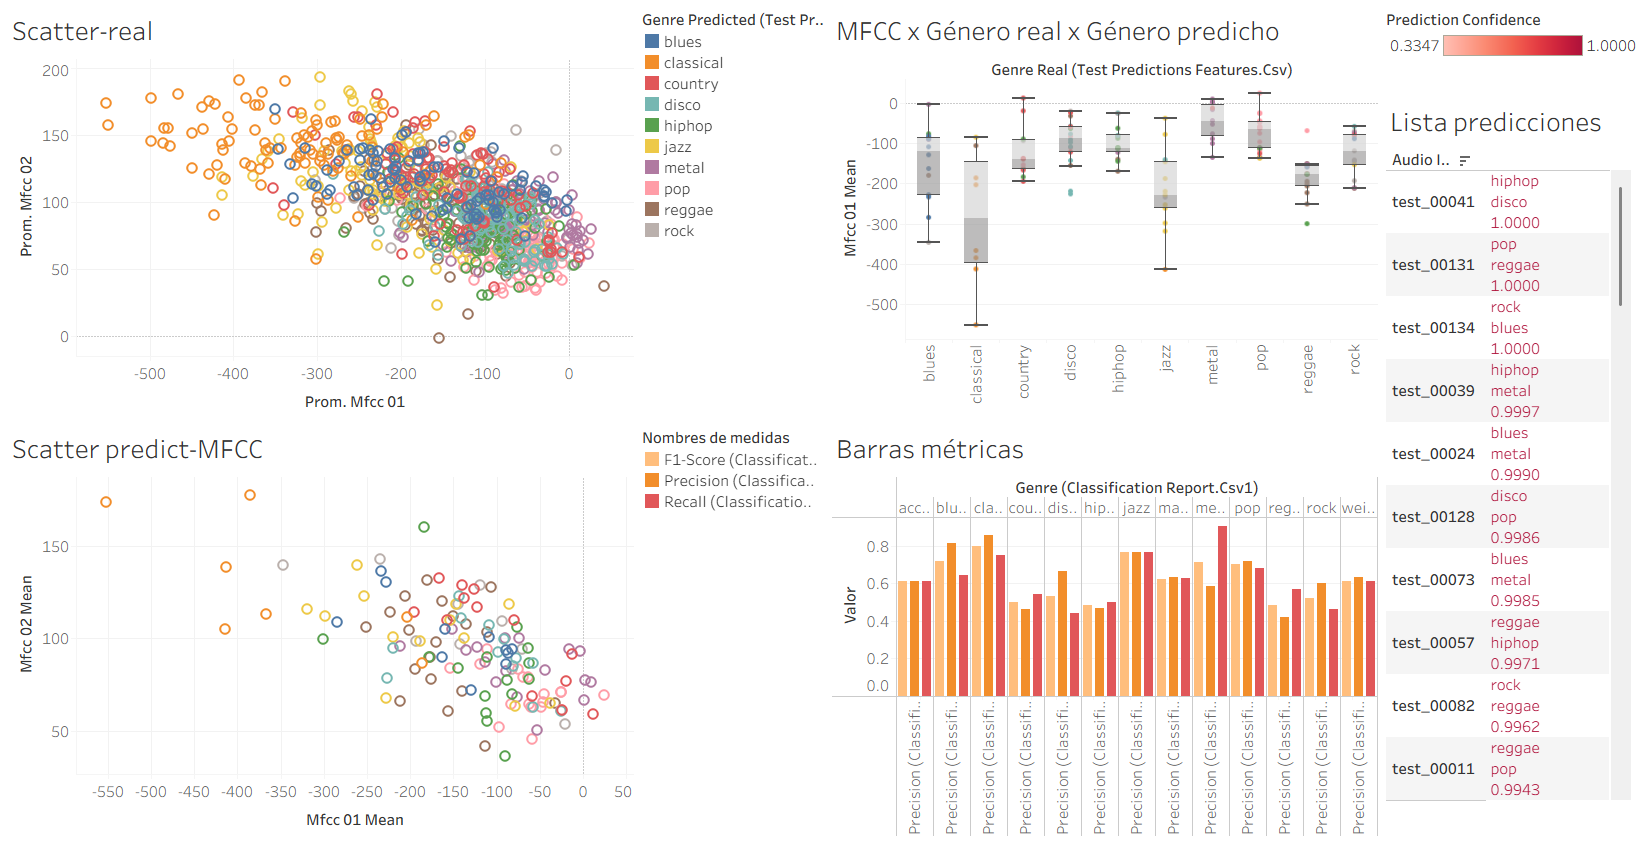

# Referencias
Ahmed, M., Rozario, U., Kabir, M. M., Aung, Z., Shin, J., & Mridha, M. F. (2024). Musical genre classification using advanced audio analysis and deep learning techniques. IEEE Open Journal of the Computer Society, 5, 457–467. https://doi.org/10.1109/OJCS.2024.3431229 . Recuperado de: https://ieeexplore.ieee.org/abstract/document/10605044 

TensorFlow. (s. f.). GTZAN: A dataset for music genre classification. TensorFlow Datasets. Recuperado el 18 de octubre de 2026, de https://www.tensorflow.org/datasets/catalog/gtzan  
